# TP — Analyse de données avec Python

### I. Importation des données

1. Importer les librairies nécessaires : Pandas, NumPy et Matplotlib

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 


2. Importer la base de données titanic.csv et extraire le type de la base de données.

In [9]:
df=pd.read_csv("titanic_1.csv")


In [7]:
print(type(df))

<class 'pandas.core.frame.DataFrame'>


### II. Exploration des données

3. Afficher les 5 premières lignes de la base de données

In [10]:
df.head()

,PassengerId,Survived,Pclass,Lname,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,Braund,Mr. Owen Harris,male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,Cumings,Mrs. John Bradley (Florence Briggs Thayer),female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,Heikkinen,Miss. Laina,female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,Futrelle,Mrs. Jacques Heath (Lily May Peel),female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,Allen,Mr. William Henry,male,35.0,0,0,373450,8.0500,NaN,S


4. Afficher les 5 dernières lignes de la base de données

In [11]:
df.tail()

,PassengerId,Survived,Pclass,Lname,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
151,152,1,1,Pears,Mrs. Thomas (Edith Wearne),female,22.0,1,0,113776,66.6000,C2,S
152,153,0,3,Meo,Mr. Alfonzo,male,55.5,0,0,A.5. 11206,8.0500,NaN,S
153,154,0,3,van Billiard,Mr. Austin Blyler,male,40.5,0,2,A/5. 851,14.5000,NaN,S
154,155,0,3,Olsen,Mr. Ole Martin,male,NaN,0,0,Fa 265302,7.3125,NaN,S
155,156,0,1,Williams,Mr. Charles Duane,male,51.0,0,1,PC 17597,61.3792,NaN,C


5. Afficher le nombre de lignes et de colonnes de la base de données.

In [15]:
print(df.shape)

(156, 13)


6. Afficher le type de chaque variable ainsi que le nombre de valeurs non nulles par
colonne (méthode info()).

In [17]:
print(df.info)

<bound method DataFrame.info of      PassengerId  Survived  Pclass         Lname  \
0              1         0       3        Braund   
1              2         1       1       Cumings   
2              3         1       3     Heikkinen   
3              4         1       1      Futrelle   
4              5         0       3         Allen   
..           ...       ...     ...           ...   
151          152         1       1         Pears   
152          153         0       3           Meo   
153          154         0       3  van Billiard   
154          155         0       3         Olsen   
155          156         0       1      Williams   

                                            Name     Sex   Age  SibSp  Parch  \
0                                Mr. Owen Harris    male  22.0      1      0   
1     Mrs. John Bradley (Florence Briggs Thayer)  female  38.0      1      0   
2                                    Miss. Laina  female  26.0      0      0   
3             Mrs. Jacq

7. Afficher un résumé statistique des variables numériques (méthode describe()).

In [18]:
print(df.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   156.000000  156.000000  156.000000  126.000000  156.000000   
mean     78.500000    0.346154    2.423077   28.141508    0.615385   
std      45.177428    0.477275    0.795459   14.613880    1.056235   
min       1.000000    0.000000    1.000000    0.830000    0.000000   
25%      39.750000    0.000000    2.000000   19.000000    0.000000   
50%      78.500000    0.000000    3.000000   26.000000    0.000000   
75%     117.250000    1.000000    3.000000   35.000000    1.000000   
max     156.000000    1.000000    3.000000   71.000000    5.000000   

            Parch        Fare  
count  156.000000  156.000000  
mean     0.397436   28.109587  
std      0.870146   39.401047  
min      0.000000    6.750000  
25%      0.000000    8.003150  
50%      0.000000   14.454200  
75%      0.000000   30.371850  
max      5.000000  263.000000  


8. Visualiser la distribution d'âge des passagers (utiliser l'histogramme). Commenter

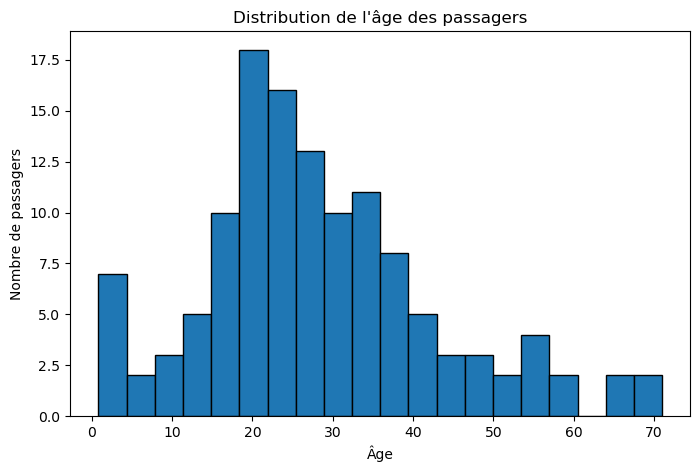

In [19]:
plt.figure(figsize=(8, 5))
plt.hist(df["Age"].dropna(), bins=20, edgecolor="black")  # dropna : on ignore les âges manquants
plt.title("Distribution de l'âge des passagers")
plt.xlabel("Âge")
plt.ylabel("Nombre de passagers")
plt.show()

9. Afficher, sous forme de diagramme en barres, le nombre de passagers par classe
(Pclass).


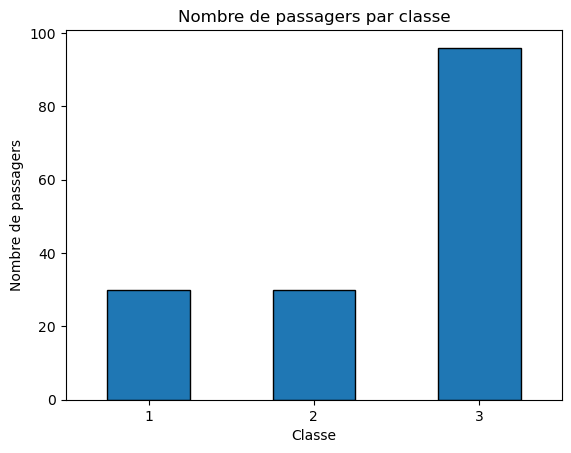

In [23]:

df["Pclass"].value_counts().sort_index().plot(kind="bar", edgecolor="black")
plt.title("Nombre de passagers par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre de passagers")
plt.xticks(rotation=0)
plt.show()

10. Afficher le taux de survie des passagers par sexe

In [24]:
taux_survie_sexe = df.groupby("Sex")["Survived"].mean() * 100
print(taux_survie_sexe)

Sex
female    71.428571
male      14.000000
Name: Survived, dtype: float64


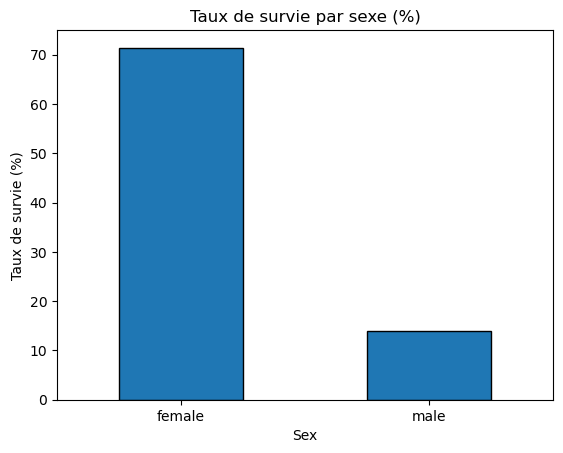

In [27]:
# Visualisation du taux de survie par sexe
taux_survie_sexe.plot(kind="bar", edgecolor="black")
plt.title("Taux de survie par sexe (%)")
plt.ylabel("Taux de survie (%)")
plt.xticks(rotation=0)
plt.show()

11. Calculer la moyenne des passagers survécus par sexe.

In [28]:
print(df.groupby("Sex")["Survived"].mean())

Sex
female    0.714286
male      0.140000
Name: Survived, dtype: float64


12. Comment le taux de survie diffère-t-il entre les différentes classes du Titanic ?

In [29]:
taux_survie_classe = df.groupby("Pclass")["Survived"].mean() * 100
print(taux_survie_classe)

Pclass
1    40.000000
2    46.666667
3    29.166667
Name: Survived, dtype: float64


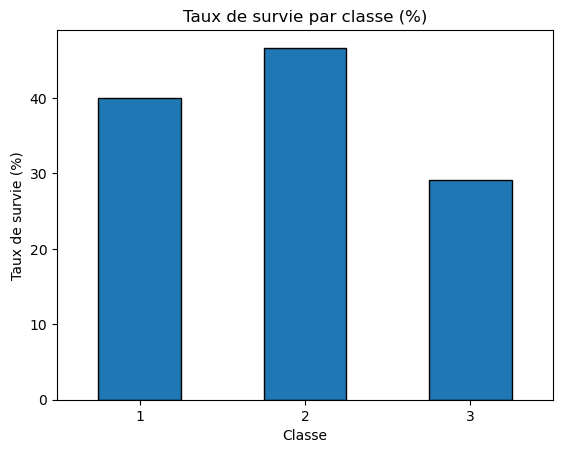

In [33]:
# visualisation du taux de survie par classe 
taux_survie_classe.plot(kind="bar", edgecolor="black")
plt.title("Taux de survie par classe (%)")
plt.xlabel("Classe")
plt.ylabel("Taux de survie (%)")
plt.xticks(rotation=0)
plt.show()

13. Calculer la moyenne des passagers survivants par classe.


In [39]:


print(df.groupby("Pclass")["Survived"].mean())

Pclass
1    0.400000
2    0.466667
3    0.291667
Name: Survived, dtype: float64


14. Afficher les passagers qui sont des hommes de moins de 25 ans et calculer leur taux
de survie moyen.

In [40]:
hommes_moins_25 = df[(df["Sex"] == "male") & (df["Age"] < 25)]  # filtre combiné : & + parenthèses obligatoires
print(hommes_moins_25)

     PassengerId  Survived  Pclass          Lname                        Name  \
0              1         0       3         Braund             Mr. Owen Harris   
7              8         0       3        Palsson       Master. Gosta Leonard   
12            13         0       3    Saundercock           Mr. William Henry   
16            17         0       3           Rice              Master. Eugene   
27            28         0       1        Fortune       Mr. Charles Alexander   
37            38         0       3           Cann          Mr. Ernest Charles   
50            51         0       3         Panula          Master. Juha Niilo   
51            52         0       3      Nosworthy           Mr. Richard Cater   
59            60         0       3        Goodwin   Master. William Frederick   
60            61         0       3     Sirayanian                   Mr. Orsen   
63            64         0       3          Skoog              Master. Harald   
67            68         0  

In [42]:
# Taux de survie moyen de ce groupe
print(hommes_moins_25["Survived"].mean())

0.12121212121212122


15. Combien de personnes ont survécu par rapport à la totalité des passagers ?

In [41]:
nb_survivants = df["Survived"].sum()   # somme des 1 = nombre de survivants
nb_total = len(df)
print(f"{nb_survivants} survivants sur {nb_total} passagers, soit {nb_survivants / nb_total:.2%}")

54 survivants sur 156 passagers, soit 34.62%


16. Afficher la matrice de corrélation entre les variables numériques (Age, Fare, SibSp,
Parch, Survived) et commenter les corrélations les plus fortes.


In [43]:
corr = df[["Age", "Fare", "SibSp", "Parch", "Survived"]].corr()
print(corr)

               Age      Fare     SibSp     Parch  Survived
Age       1.000000  0.024494 -0.393500 -0.215169 -0.120416
Fare      0.024494  1.000000  0.271997  0.254822  0.029343
SibSp    -0.393500  0.271997  1.000000  0.399040 -0.066943
Parch    -0.215169  0.254822  0.399040  1.000000  0.039435
Survived -0.120416  0.029343 -0.066943  0.039435  1.000000


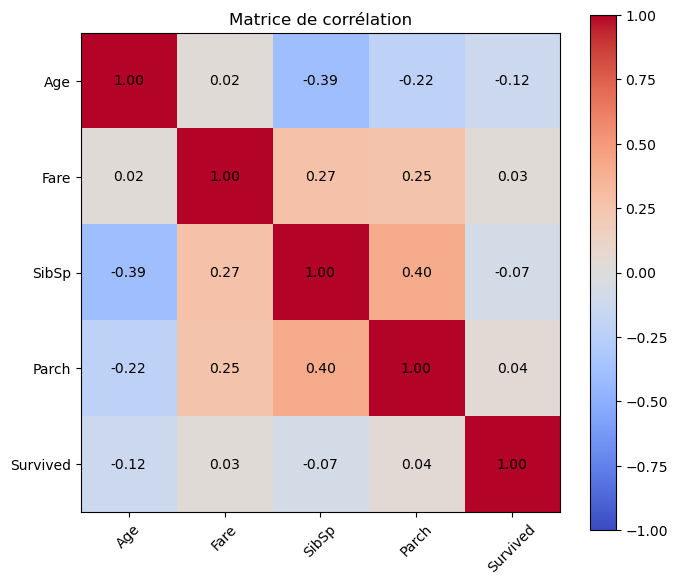

In [44]:

# Visualisation de la matrice (heatmap avec Matplotlib)
plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45)
plt.yticks(range(len(corr)), corr.columns)
# Affichage de la valeur dans chaque case
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

### III. Prétraitement des données

17. Identifier les colonnes contenant des valeurs manquantes et compter le nombre de
valeurs manquantes par colonne.


In [46]:
# Copie de travail pour le prétraitement (on garde df intact)
df_clean = df.copy()

In [47]:
manquants = df_clean.isnull().sum()
print(manquants[manquants > 0]) 

Age          30
Cabin       125
Embarked      1
dtype: int64


18. Remplacer les valeurs manquantes de la variable Age par la médiane des âges

In [49]:
mediane_age = df_clean["Age"].median()
df_clean["Age"] = df_clean["Age"].fillna(mediane_age)

19. Remplacer les valeurs manquantes de la variable Embarked par la valeur la plus
fréquente (le mode).

In [51]:
mode_embarked = df_clean["Embarked"].mode()[0]   # mode() renvoie une Series, [0] prend la valeur
df_clean["Embarked"] = df_clean["Embarked"].fillna(mode_embarked)

20. La colonne Cabin contient un très grand nombre de valeurs manquantes : proposer et
appliquer une solution (par exemple, supprimer la colonne, ou créer une variable
binaire indiquant si la cabine est connue).


In [52]:
df_clean["CabinKnown"] = df_clean["Cabin"].notnull().astype(int)  # 1 = cabine connue, 0 = inconnue
df_clean = df_clean.drop(columns=["Cabin"])

In [53]:
print(df_clean.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Lname          0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
CabinKnown     0
dtype: int64


21. Encoder la variable Sex en variable numérique (0 pour female, 1 pour male).
    

In [54]:
df_clean["Sex"] = df_clean["Sex"].map({"female": 0, "male": 1})

22. Créer une nouvelle variable FamilySize égale à SibSp + Parch + 1, représentant la
taille de la famille du passager à bord.

In [55]:
df_clean["FamilySize"] = df_clean["SibSp"] + df_clean["Parch"] + 1

23. Supprimer les colonnes non exploitables pour l'analyse (PassengerId, Name, Ticket).

In [56]:
df_clean = df_clean.drop(columns=["PassengerId", "Name", "Lname", "Ticket"])

24. Afficher les 5 premières lignes de la base de données finale, après prétraitement.

In [57]:
df_clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,CabinKnown,FamilySize
0,0,3,1,22.0,1,0,7.2500,S,0,2
1,1,1,0,38.0,1,0,71.2833,C,1,2
2,1,3,0,26.0,0,0,7.9250,S,0,1
3,1,1,0,35.0,1,0,53.1000,S,1,2
4,0,3,1,35.0,0,0,8.0500,S,0,1
